# Linear Optimal Control — Forward-Backward Sweep (Nonlinear ODE)
**Author:** Achyutan Veeraraghavan
**Mentor:** Dr. Padmanabhan Seshaiyer (George Mason University)

## Model overview
Four-compartment **NONLINEAR** ODE system (N, L, M, H) with bilinear social contagion terms ($\beta_1 LM$, $\beta_1 LH$, $\beta_2 MH$), so the adjoint equations contain state × co-state products.

| Compartment | Meaning |
|---|---|
| $N(t)$ | No risk (protected via education) |
| $L(t)$ | Low risk (susceptible) |
| $M(t)$ | Medium risk |
| $H(t)$ | High risk |

**Control:** composite intervention intensity $\alpha_w(t)$, decomposed with fixed weights into $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$.

## Cost functional
$$V(\alpha_w) = \int_0^T \left(\omega_1 M(t) + \omega_2 H(t) + \lambda_w\alpha_w(t)\right)dt$$

This notebook takes the original quadratic-cost version (`Quadratic_Optimal_Control_Forward_Backward_Sweeping_NonLinear_ODE.ipynb`) and changes only the cost term. Because the Hamiltonian is then affine in $\alpha_w$, $\partial\hat{H}/\partial\alpha_w = 0$ has no interior solution, and Pontryagin's Minimum Principle gives a bang-bang control with a possible singular arc.

## What changes vs the quadratic (original) version
| Step | Quadratic (original) | Linear cost (this notebook) |
|---|---|---|
| Cost term in $\hat{H}$ | $\frac{\lambda_w}{2}\alpha_w^2$ | $\lambda_w\alpha_w$ |
| Step 1: Hamiltonian | slide 19 | same, with $\lambda_w\alpha_w$ in place of $\frac{\lambda_w}{2}\alpha_w^2$ |
| Step 2: Optimality condition | $\alpha_w^* = -C/\lambda_w$ | sign of $\Phi = \lambda_w + C$; singular arc $\alpha_w = -A_2/B_2$ |
| Step 3: Adjoint equations | slide 20 | **identical** |
| Step 4: Transversality | $W_i(T) = 0$ | **identical** |
| State ODEs | slide 5 | **identical** |
| Step 5: Control update | pointwise $\alpha_w^*$, 0.5 blend | bounded gradient step (L-BFGS-B) using $\Phi = \partial V/\partial\alpha_w$ |
| After convergence | — | singular-arc checks |

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, minimize_scalar
import matplotlib.pyplot as plt
%matplotlib inline

## Section 1 — Parameters

In [2]:
# --- Level 2 transmission parameters ---
# beta1 : social media contagion rate L->M (moderate escalation via peer contact)
#         Evidence: WHO HBSC 2024 (N=280,000 adolescents, 44 countries) found
#         problematic social media use rose 7%->11% over ~200 weeks; scaled for
#         peer contagion amplification per Mallick et al. (2024), Scientific Reports.
#         Value: 0.15/week
beta1 = 0.15

# beta2 : escalation rate M->H (severe contagion via MH interaction)
#         Evidence: US adolescent depression rates rose 8.7% (2005) to 15.8% (2019)
#         over ~728 weeks per Burgess (2025), SAGE Journals; scaled for M*H peer
#         contact amplification. Must satisfy beta2 > gamma2 for endemic feasibility.
#         Value: 0.10/week
beta2 = 0.10

# delta : rate at which educated (N) people lose protection and return to L
#         Evidence: Stockholm MDD Cohort (N=9,124; Pubmed 2025) found median time
#         from remission to recurrence in adolescents was 379 days (~54 weeks),
#         giving decay rate 1/54 ≈ 0.018/week, rounded to 0.02/week.
#         Value: 0.02/week
delta = 0.02

# --- Level 3 composite control weights (fixed, sum to 1) ---
# v_alpha : proportion of alpha_w allocated to prevention (L->N)
#           At alpha_w=1.0: alpha = 0.4*1.0 = 0.40/week (prevention rate)
#           Evidence: DMHL meta-analysis (Musiat et al. 2024, JMIR; 144 interventions,
#           SMD=0.65 on literacy outcomes) supports ~40% literacy improvement over
#           10-week programs ≈ 0.08/week directly; v_alpha*alpha_max = 0.40/week.
# v1      : proportion allocated to medium-risk recovery (M->L)
#           At alpha_w=1.0: gamma1 = 0.35*1.0 = 0.35/week
#           Evidence: Untreated remission 8-18% per 12 weeks (Linde et al. 2022,
#           J Affective Disorders) + DMHL intervention effect (SMD=0.42).
#           Note: gamma1 = 0.35 > gamma1_target = 0.05 at alpha_w=1.0 because
#           alpha_w represents maximum intervention; at typical alpha_w* ≈ 0.15,
#           gamma1 ≈ 0.05, consistent with evidence.
# v2      : proportion allocated to high-risk recovery (H->M)
#           At alpha_w=1.0: gamma2 = 0.25*1.0 = 0.25/week
#           Evidence: TADS RCT (March et al. 2009, N=439 adolescents): 65% recovery
#           at week 36 with treatment ≈ 1.8%/week; at typical alpha_w* ≈ 0.28,
#           gamma2 ≈ 0.07, consistent with TADS evidence.
#           Feasibility check: gamma2 < beta2 requires alpha_w < beta2/v2 = 0.10/0.25
#           = 0.40 for endemic equilibrium. At optimal alpha_w* this is satisfied.
v_alpha = 0.4
v1      = 0.35
v2      = 0.25
assert abs(v_alpha + v1 + v2 - 1.0) < 1e-9, "Weights must sum to 1"

# --- Loss function parameters ---
# w1    : societal cost weight for time spent in M
#         Value: 1.0 (baseline unit)
# w2    : societal cost weight for time spent in H (w2 > w1)
#         Evidence: Burgess (2025) documents US adolescent suicide rates up 47.5%
#         since 2000 (2nd leading cause of death); Nature Human Behaviour (2025)
#         UK data (N=3,340) shows clinical-level conditions carry substantially
#         greater burden. Ratio 5:1 reflects clinical cost-of-illness literature.
#         Value: 5.0
# lam_w : financial/resource cost of composite intervention (LINEAR coefficient)
#         Set to 1.0 (neutral baseline equal to w1) so ratio lam_w/w1 = 1,
#         placing intervention cost and societal burden on the same scale.
#         Value: 1.0
w1    = 1.0
w2    = 5.0
lam_w = 1.0

# --- Control bounds ---
# alpha_w in [0, alpha_max]; bang-bang arcs sit at 0 or alpha_max.
alpha_max = 1.0

# --- Time horizon ---
# T     : length of simulation (e.g. 52 weeks = 1 year)
# n_t   : number of discrete time points in the grid
T   = 52.0
n_t = 1000
t_grid = np.linspace(0, T, n_t)

h = t_grid[1] - t_grid[0]   # grid step for the fixed-step RK4 sweeps

# --- Convergence settings ---
# The control update is a bounded L-BFGS-B step, which stops when the relative
# reduction in V per iteration falls below ftol (or the projected gradient
# falls below gtol).
max_iter = 3000
ftol     = 1e-15
gtol     = 1e-12

# --- Singular-arc detection settings ---
phi_tol     = 1e-4 * lam_w   # |Phi| below this counts as Phi = 0
min_arc_len = 1.0            # weeks; shorter runs are just zero crossings

## Section 2 — Initial conditions

In [3]:
# These would come from your MLP model outputs in practice.
# They represent the fraction of the population in each compartment at t=0.
# Must sum to 1.

N0 = 0.000   # 0.0% protected / no risk — matches MLP predictions
L0 = 0.268   # 26.8% low risk susceptible
M0 = 0.268   # 26.8% medium risk
H0 = 0.464   # 46.4% high risk

assert abs(N0 + L0 + M0 + H0 - 1.0) < 1e-9, "Initial conditions must sum to 1"
y0_state = [N0, L0, M0, H0]

## Section 3 — Step 1: Hamiltonian (slide 19), with $\lambda_w\alpha_w$ in place of $\frac{\lambda_w}{2}\alpha_w^2$

$$\hat{H}(N,L,M,H) = \omega_1 M + \omega_2 H + \lambda_w\alpha_w + W_N(\alpha L - \delta N) + W_L(-\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N)$$
$$+\,W_M(\beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H) + W_H(\beta_2 MH - \gamma_2 H)$$

$W_N, W_L, W_M, W_H$ are all co-state variables for the Hamiltonian. Need all in terms of $\alpha_w$: $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$

$$\hat{H}(N,L,M,H) = \omega_1 M + \omega_2 H + \lambda_w\alpha_w + W_N(v_\alpha\alpha_w L - \delta N) + W_L(-\beta_1 LM - \beta_1 LH + v_1\alpha_w M - v_\alpha\alpha_w L + \delta N)$$
$$+\,W_M(\beta_1 LM + \beta_1 LH - \beta_2 MH - v_1\alpha_w M + v_2\alpha_w H) + W_H(\beta_2 MH - v_2\alpha_w H)$$

$$\hat{H}(N,L,M,H) = \lambda_w\alpha_w + \alpha_w[v_\alpha L(W_N - W_L) + v_1 M(W_L - W_M) + v_2 H(W_M - W_H)]$$
$$+\,\omega_1 M + \omega_2 H + \delta N(W_L - W_N) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M)$$

## Section 4 — Step 2: Optimality condition (slide 19) → switching function

Need to take all terms with $\alpha_w$ for differentiation (same $C$ as the quadratic version):

$$C = [v_\alpha L(W_N - W_L) + v_1 M(W_L - W_M) + v_2 H(W_M - W_H)]$$
$$\hat{H}_{\alpha_w} = \lambda_w\alpha_w + \alpha_w C = \alpha_w(\lambda_w + C)$$
$$\Phi(t) = \frac{\partial\hat{H}}{\partial\alpha_w} = \lambda_w + C$$

$\hat{H}$ is linear in $\alpha_w$, so it is minimized at an endpoint unless $\Phi$ vanishes on an interval:

$$\alpha_w^*(t) = \begin{cases} \alpha_w^{\max} & \Phi(t) < 0 \\ 0 & \Phi(t) > 0 \\ \alpha_w^{\text{sing}}(t) = -A_2(t)/B_2(t) & \Phi(t) = 0 \text{ on an interval (singular arc, Section 10)} \end{cases}$$

In [4]:
def compute_switching_function(L, M, H, p_N, p_L, p_M, p_H):
    """
    Step 2 — Switching function for the LINEAR cost.

    C(t)   = v_alpha*L*(W_N - W_L) + v1*M*(W_L - W_M) + v2*H*(W_M - W_H)   (same C as the slides)
    Phi(t) = dH/d(alpha_w) = lam_w + C(t)
    """
    C = (v_alpha * L * (p_N - p_L)
       + v1      * M * (p_L - p_M)
       + v2      * H * (p_M - p_H))
    return lam_w + C

## Section 5 — Step 3: Adjoint (co-state) equations (slide 20)

**Identical to the quadratic version**: the linear cost term $\lambda_w\alpha_w$ has no state dependence, so it contributes nothing to $\dot W_i = -\partial\hat{H}/\partial x_i$.

$$\hat{H}_N = -\delta N(W_N - W_L) \;\rightarrow\; \dot{W}_N = -\frac{\partial\hat{H}}{\partial N} = \delta(W_N - W_L)$$
$$\hat{H}_L = v_\alpha\alpha_w L(W_N - W_L) + \beta_1 L(M+H)(W_M - W_L) \;\rightarrow\; \dot{W}_L = -\frac{\partial\hat{H}}{\partial L} = v_\alpha\alpha_w(W_L - W_N) + \beta_1(M+H)(W_L - W_M)$$
$$\hat{H}_M = v_1\alpha_w M(W_L - W_M) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M) + \omega_1 M$$
$$\rightarrow\; \dot{W}_M = -\frac{\partial\hat{H}}{\partial M} = v_1\alpha_w(W_M - W_L) + \beta_1 L(W_L - W_M) + \beta_2 H(W_M - W_H) - \omega_1$$
$$\hat{H}_H = v_2\alpha_w H(W_M - W_H) + \beta_1 L(M+H)(W_M - W_L) + \beta_2 MH(W_H - W_M) + \omega_2 H$$
$$\rightarrow\; \dot{W}_H = -\frac{\partial\hat{H}}{\partial H} = v_2\alpha_w(W_H - W_M) + \beta_1 L(W_L - W_M) + \beta_2 M(W_M - W_H) - \omega_2$$

In the code, `p_N, p_L, p_M, p_H` are $W_N, W_L, W_M, W_H$.

In [5]:
def adjoint_rhs(t, p, y, alpha_w_t):
    """
    Step 3 — Adjoint (co-state) ODE right-hand sides, written exactly as on slide 20.
    p_N, p_L, p_M, p_H in the code are W_N, W_L, W_M, W_H on the slides.

    IDENTICAL to the quadratic version: the linear cost term lam_w*alpha_w has
    no state dependence, so it contributes nothing to the adjoint equations.
    """
    p_N, p_L, p_M, p_H = p
    N_t, L_t, M_t, H_t = y

    # Recover Level 2 control values from alpha_w at this time point
    alpha_t  = v_alpha * alpha_w_t
    gamma1_t = v1      * alpha_w_t
    gamma2_t = v2      * alpha_w_t

    # p_dot_N = delta*(p_N - p_L)
    p_dot_N = delta * (p_N - p_L)

    # p_dot_L = v_alpha*alpha_w*(p_L - p_N) + beta1*(M+H)*(p_L - p_M)
    p_dot_L = alpha_t * (p_L - p_N) + beta1 * (M_t + H_t) * (p_L - p_M)

    # p_dot_M = v1*alpha_w*(p_M - p_L) + beta1*L*(p_L - p_M) + beta2*H*(p_M - p_H) - w1
    p_dot_M = (gamma1_t * (p_M - p_L) + beta1 * L_t * (p_L - p_M)
               + beta2 * H_t * (p_M - p_H) - w1)

    # p_dot_H = v2*alpha_w*(p_H - p_M) + beta1*L*(p_L - p_M) + beta2*M*(p_M - p_H) - w2
    p_dot_H = (gamma2_t * (p_H - p_M) + beta1 * L_t * (p_L - p_M)
               + beta2 * M_t * (p_M - p_H) - w2)

    return [p_dot_N, p_dot_L, p_dot_M, p_dot_H]

## Section 6 — Step 4: Transversality conditions (slide 20)

No terminal cost needed (already doing running cost):

$$W_N(T) = W_L(T) = W_M(T) = W_H(T) = 0$$

Directly represents no additional penalties at the end of $[0, T]$. Applied as the starting values of the backward sweep.

## Section 7 — State ODEs (slide 5)

With $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$:

$$\frac{dN}{dt} = \alpha L - \delta N$$
$$\frac{dL}{dt} = -\beta_1 LM - \beta_1 LH + \gamma_1 M - \alpha L + \delta N$$
$$\frac{dM}{dt} = \beta_1 LM + \beta_1 LH - \beta_2 MH - \gamma_1 M + \gamma_2 H$$
$$\frac{dH}{dt} = \beta_2 MH - \gamma_2 H$$

In [6]:
def state_rhs(t, y, alpha_w_t):
    """
    Four NONLINEAR NLMH state ODEs, written exactly as on slide 5.

    dN/dt = alpha*L - delta*N
    dL/dt = -beta1*L*M - beta1*L*H + gamma1*M - alpha*L + delta*N
    dM/dt = beta1*L*M + beta1*L*H - beta2*M*H - gamma1*M + gamma2*H
    dH/dt = beta2*M*H - gamma2*H
    """
    N, L, M, H = y

    # Decompose alpha_w into Level 2 components using fixed weights
    alpha_t  = v_alpha * alpha_w_t
    gamma1_t = v1      * alpha_w_t
    gamma2_t = v2      * alpha_w_t

    dN = alpha_t * L - delta * N
    dL = -beta1 * L * M - beta1 * L * H + gamma1_t * M - alpha_t * L + delta * N
    dM = beta1 * L * M + beta1 * L * H - beta2 * M * H - gamma1_t * M + gamma2_t * H
    dH = beta2 * M * H - gamma2_t * H

    return [dN, dL, dM, dH]

## Section 8 — Step 5: Forward-backward sweep

Same forward and backward sweeps as the quadratic version. Only the control update changes: $\Phi(t) = \partial V/\partial\alpha_w(t)$ is used as the gradient in a bounded L-BFGS-B step on $\alpha_w \in [0, \alpha_w^{\max}]$, because a pointwise bang-bang update cannot converge on a singular arc (the optimal value there lies strictly between 0 and $\alpha_w^{\max}$).

In [7]:
# Fixed-step RK4 on t_grid: the control update below needs the exact gradient
# dV/d(alpha_w)(t) = Phi(t) at every grid point, so states and co-states are
# integrated on the same grid as alpha_w.

def forward_sweep(alpha_w):
    """State ODEs forward from t = 0 to T (RK4 on t_grid)."""
    Y = np.zeros((n_t, 4)); Y[0] = y0_state
    for i in range(n_t - 1):
        a0, a1 = alpha_w[i], alpha_w[i + 1]; am = 0.5 * (a0 + a1)
        t, y = t_grid[i], Y[i]
        k1 = np.array(state_rhs(t,         y,             a0))
        k2 = np.array(state_rhs(t + h / 2, y + h / 2 * k1, am))
        k3 = np.array(state_rhs(t + h / 2, y + h / 2 * k2, am))
        k4 = np.array(state_rhs(t + h,     y + h * k3,     a1))
        Y[i + 1] = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return Y


def backward_sweep(Y, alpha_w):
    """Adjoint ODEs backward from t = T to 0 (RK4 on t_grid).
    Transversality (Step 4): p_N(T) = p_L(T) = p_M(T) = p_H(T) = 0."""
    P = np.zeros((n_t, 4))
    for i in range(n_t - 1, 0, -1):
        a1, a0 = alpha_w[i], alpha_w[i - 1]; am = 0.5 * (a0 + a1)
        y1, y0 = Y[i], Y[i - 1]; ym = 0.5 * (y0 + y1)
        t, p = t_grid[i], P[i]
        k1 = np.array(adjoint_rhs(t,         p,             y1, a1))
        k2 = np.array(adjoint_rhs(t - h / 2, p - h / 2 * k1, ym, am))
        k3 = np.array(adjoint_rhs(t - h / 2, p - h / 2 * k2, ym, am))
        k4 = np.array(adjoint_rhs(t - h,     p - h * k3,     y0, a0))
        P[i - 1] = p - h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return P


def linear_cost(Y, alpha_w):
    """Linear cost functional V = integral(w1*M + w2*H + lam_w*alpha_w) dt."""
    return np.trapezoid(w1 * Y[:, 2] + w2 * Y[:, 3] + lam_w * alpha_w, t_grid)


def switching_trajectory(Y, P):
    return np.array([compute_switching_function(Y[i, 1], Y[i, 2], Y[i, 3], *P[i])
                     for i in range(n_t)])


def forward_backward_sweep():
    """
    Step 5 — Forward-backward sweep with a bounded gradient update.

    Every iteration does the same two sweeps as the quadratic version:
        SUB-STEP 1  forward sweep  (state ODEs,   t = 0 -> T)
        SUB-STEP 2  backward sweep (adjoint ODEs, t = T -> 0)
    SUB-STEP 3 changes: Phi(t) is exactly dV/d(alpha_w)(t), so it is used as the
    gradient in a bounded quasi-Newton (L-BFGS-B) step on alpha_w in [0, alpha_max].
    A pointwise bang-bang update (0 or alpha_max from the sign of Phi) cannot
    converge when the optimum contains a singular arc, because the optimal
    value there lies strictly between 0 and alpha_max.
    """
    # -------------------------------------------------------------------------
    # PRELIMINARY — baseline V with zero control (no intervention)
    # -------------------------------------------------------------------------
    def state_rhs_zero(t, y):
        return state_rhs(t, y, alpha_w_t=0.0)

    sol_base = solve_ivp(state_rhs_zero, [0, T], y0_state,
                         t_eval=t_grid, method='RK45', dense_output=False)
    M_base = sol_base.y[2]
    H_base = sol_base.y[3]
    V_baseline = np.trapezoid(w1 * M_base + w2 * H_base, t_grid)

    print(f"Baseline V (no intervention): {V_baseline:.4f}")
    print("=" * 60)

    trap_w = np.full(n_t, h); trap_w[0] = trap_w[-1] = h / 2

    def V_and_gradient(alpha_w):
        Y = forward_sweep(alpha_w)          # SUB-STEP 1
        P = backward_sweep(Y, alpha_w)      # SUB-STEP 2
        return linear_cost(Y, alpha_w), switching_trajectory(Y, P) * trap_w

    history = []        # relative L1 change in alpha_w at each iteration
    prev = [np.zeros(n_t)]

    def record(alpha_w):
        rel = np.sum(np.abs(alpha_w - prev[0])) / (np.sum(np.abs(prev[0])) + 1e-8)
        history.append(rel); prev[0] = alpha_w.copy()

    # SUB-STEP 3 + 4: bounded update and convergence test inside L-BFGS-B
    res = minimize(V_and_gradient, np.zeros(n_t), jac=True, method='L-BFGS-B',
                   bounds=[(0.0, alpha_max)] * n_t, callback=record,
                   options={'maxiter': max_iter, 'ftol': ftol, 'gtol': gtol})
    print(f"Converged at iteration {res.nit}.  ({res.message})")

    alpha_w_opt = res.x
    Y = forward_sweep(alpha_w_opt)
    P = backward_sweep(Y, alpha_w_opt)
    phi_traj = switching_trajectory(Y, P)
    V_opt = linear_cost(Y, alpha_w_opt)

    print(f"\nOptimal V*              : {V_opt:.4f}")
    print(f"Baseline V (no control) : {V_baseline:.4f}")
    print(f"Burden reduction        : {100*(V_baseline - V_opt)/V_baseline:.1f}%")

    states   = {'N': Y[:, 0], 'L': Y[:, 1], 'M': Y[:, 2], 'H': Y[:, 3]}
    costates = {'p_N': P[:, 0], 'p_L': P[:, 1], 'p_M': P[:, 2], 'p_H': P[:, 3]}
    return alpha_w_opt, phi_traj, states, costates, V_opt, V_baseline, history, res.nit

## Section 9 — Run the sweep

In [8]:
alpha_w_opt, phi_traj, states, costates, V_opt, V_baseline, history, n_iter = forward_backward_sweep()

# Decompose optimal alpha_w* back into Level 2 components
alpha_opt  = v_alpha * alpha_w_opt
gamma1_opt = v1      * alpha_w_opt
gamma2_opt = v2      * alpha_w_opt

Baseline V (no intervention): 219.3598


Converged at iteration 433.  (CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH)

Optimal V*              : 32.7362
Baseline V (no control) : 219.3598
Burden reduction        : 85.1%


## Section 10 — Singular arc check

On a singular arc $\Phi(t) \equiv 0$ over an interval, so $\dot\Phi = 0$ and $\ddot\Phi = 0$ there too. With $\Delta_1 = W_N - W_L$, $\Delta_2 = W_L - W_M$, $\Delta_3 = W_M - W_H$:

**First derivative.** Substituting the state and adjoint ODEs into $\dot\Phi$, every $\alpha_w$ term cancels ($B(t) = 0$), leaving

$$\dot\Phi = A(t) = c_1\Delta_1 + c_2\Delta_2 + c_3\Delta_3 + c_0$$
$$c_1 = v_\alpha[\delta(N+L) - \beta_1 L(M+H)]$$
$$c_2 = \beta_1(v_1 - v_\alpha)L(M+H) + v_1\beta_1 M(M+H-L) - v_1\beta_2 MH$$
$$c_3 = \beta_2 H(v_2 H - v_1 M)$$
$$c_0 = v_1\omega_1 M + v_2(\omega_2 - \omega_1)H$$

so $\dot\Phi = 0$ cannot determine $\alpha_w$.

**Second derivative.** Differentiating again with the product rule and splitting every derivative into its $\alpha_w$ part and the rest:

| | $\alpha_w$ part ($\times\alpha_w$) | part without $\alpha_w$ |
|---|---|---|
| $\dot N$ | $v_\alpha L$ | $-\delta N$ |
| $\dot L$ | $v_1 M - v_\alpha L$ | $-\beta_1 LM - \beta_1 LH + \delta N$ |
| $\dot M$ | $-v_1 M + v_2 H$ | $\beta_1 LM + \beta_1 LH - \beta_2 MH$ |
| $\dot H$ | $-v_2 H$ | $\beta_2 MH$ |
| $\dot\Delta_1$ | $v_\alpha\Delta_1$ | $\delta\Delta_1 - \beta_1(M+H)\Delta_2$ |
| $\dot\Delta_2$ | $-v_\alpha\Delta_1 + v_1\Delta_2$ | $\beta_1(M+H-L)\Delta_2 - \beta_2 H\Delta_3 + \omega_1$ |
| $\dot\Delta_3$ | $-v_1\Delta_2 + v_2\Delta_3$ | $\beta_2(H-M)\Delta_3 + (\omega_2 - \omega_1)$ |

$$\ddot\Phi = \sum_{i=1}^{3}\left[\dot c_i\Delta_i + c_i\dot\Delta_i\right] + \dot c_0 = A_2(t) + B_2(t)\,\alpha_w$$

where $B_2$ collects every $\alpha_w$ term and $A_2$ everything else. Setting $\ddot\Phi = 0$:

$$\alpha_w^{\text{sing}}(t) = -\frac{A_2(t)}{B_2(t)}$$

**A singular arc is valid only if**, on the interval: $\Phi = 0$ and $A(t) = 0$; $B_2(t) \neq 0$; $0 \le -A_2/B_2 \le \alpha_w^{\max}$; and $B_2(t) \le 0$ (generalized Legendre–Clebsch condition for a minimum).

In [9]:
def phi_dot_coeffs(N, L, M, H):
    """c1, c2, c3, c0 with Phi_dot = A(t) = c1*D1 + c2*D2 + c3*D3 + c0."""
    c1 = v_alpha * (delta * (N + L) - beta1 * L * (M + H))
    c2 = beta1 * (v1 - v_alpha) * L * (M + H) + v1 * beta1 * M * (M + H - L) - v1 * beta2 * M * H
    c3 = beta2 * H * (v2 * H - v1 * M)
    c0 = v1 * w1 * M + v2 * (w2 - w1) * H
    return c1, c2, c3, c0


def phi_dot_coeffs_rate(N, L, M, H, dN, dL, dM, dH):
    """Time derivatives of c1, c2, c3, c0 along a state velocity (dN, dL, dM, dH)."""
    dc1 = v_alpha * (delta * (dN + dL) - beta1 * dL * (M + H) - beta1 * L * (dM + dH))
    dc2 = (beta1 * (v1 - v_alpha) * (dL * (M + H) + L * (dM + dH))
           + v1 * beta1 * (dM * (M + H - L) + M * (dM + dH - dL))
           - v1 * beta2 * (dM * H + M * dH))
    dc3 = beta2 * (dH * (v2 * H - v1 * M) + H * (v2 * dH - v1 * dM))
    dc0 = v1 * w1 * dM + v2 * (w2 - w1) * dH
    return dc1, dc2, dc3, dc0


def split_rates(N, L, M, H, D1, D2, D3):
    """(alpha_w part, part without alpha_w) of the state and Delta derivatives."""
    g = (v_alpha * L, v1 * M - v_alpha * L, -v1 * M + v2 * H, -v2 * H)
    f = (-delta * N, -beta1 * L * M - beta1 * L * H + delta * N,
         beta1 * L * M + beta1 * L * H - beta2 * M * H, beta2 * M * H)
    dD_a = (v_alpha * D1, -v_alpha * D1 + v1 * D2, -v1 * D2 + v2 * D3)
    dD_0 = (delta * D1 - beta1 * (M + H) * D2,
            beta1 * (M + H - L) * D2 - beta2 * H * D3 + w1,
            beta2 * (H - M) * D3 + (w2 - w1))
    return g, f, dD_a, dD_0

def singular_terms(y, p):
    """Return A(t) = Phi_dot, A2(t) and B2(t), where Phi_ddot = A2 + B2*alpha_w."""
    N, L, M, H = y
    p_N, p_L, p_M, p_H = p
    D1, D2, D3 = p_N - p_L, p_L - p_M, p_M - p_H
    c = phi_dot_coeffs(N, L, M, H)
    A = c[0] * D1 + c[1] * D2 + c[2] * D3 + c[3]
    g, f, dD_a, dD_0 = split_rates(N, L, M, H, D1, D2, D3)
    dc_g = phi_dot_coeffs_rate(N, L, M, H, *g)
    dc_f = phi_dot_coeffs_rate(N, L, M, H, *f)
    D = (D1, D2, D3)
    B2 = sum(dc_g[i] * D[i] + c[i] * dD_a[i] for i in range(3)) + dc_g[3]
    A2 = sum(dc_f[i] * D[i] + c[i] * dD_0[i] for i in range(3)) + dc_f[3]
    return A, A2, B2


def runs(mask):
    """Contiguous True runs of a boolean array as (start_idx, end_idx)."""
    out, start = [], None
    for i, m in enumerate(mask):
        if m and start is None:
            start = i
        if not m and start is not None:
            out.append((start, i - 1)); start = None
    if start is not None:
        out.append((start, len(mask) - 1))
    return out

In [10]:
Y = np.column_stack([states[k] for k in 'NLMH'])
P = np.column_stack([costates[k] for k in ('p_N', 'p_L', 'p_M', 'p_H')])
A_traj, A2_traj, B2_traj = map(np.array, zip(*[singular_terms(Y[i], P[i]) for i in range(n_t)]))
sing_traj = -A2_traj / B2_traj

print("=" * 66)
print("CHECK 1 — Bang-bang structure")
print("=" * 66)
for a, b in runs(phi_traj < -phi_tol):
    print(f"  Phi < 0 on [{t_grid[a]:6.2f}, {t_grid[b]:6.2f}] wk : alpha_w in "
          f"[{alpha_w_opt[a:b+1].min():.3f}, {alpha_w_opt[a:b+1].max():.3f}]  (should be alpha_max)")
for a, b in runs(phi_traj > phi_tol):
    print(f"  Phi > 0 on [{t_grid[a]:6.2f}, {t_grid[b]:6.2f}] wk : alpha_w in "
          f"[{alpha_w_opt[a:b+1].min():.3f}, {alpha_w_opt[a:b+1].max():.3f}]  (should be 0)")

print("\n" + "=" * 66)
print("CHECK 2 — Singular arc search and validity")
print("=" * 66)
arcs = [(a, b) for a, b in runs(np.abs(phi_traj) < phi_tol)
        if t_grid[b] - t_grid[a] >= min_arc_len]
if not arcs:
    print("No sustained interval with Phi = 0  =>  pure bang-bang.")
for a, b in arcs:
    sl = slice(a + 2, b - 1)   # skip the junction grid points where alpha_w jumps
    diff = np.abs(alpha_w_opt[sl] - sing_traj[sl])
    print(f"Singular arc: t in [{t_grid[a]:.2f}, {t_grid[b]:.2f}] weeks")
    print(f"  max |Phi|                = {np.max(np.abs(phi_traj[sl])):.2e}   (should be ~0)")
    print(f"  max |A(t)| = |Phi_dot|   = {np.max(np.abs(A_traj[sl])):.2e}   (should be ~0)")
    print(f"  B2 range                 = [{B2_traj[sl].min():.4f}, {B2_traj[sl].max():.4f}]"
          f"   (nonzero, and <= 0 for Legendre-Clebsch)")
    print(f"  -A2/B2 range             = [{sing_traj[sl].min():.4f}, {sing_traj[sl].max():.4f}]"
          f"   (must lie in [0, {alpha_max}])")
    print(f"  |alpha_w - (-A2/B2)|     : median {np.median(diff):.1e}, 95th pct {np.percentile(diff, 95):.1e}")
    ok = (np.max(np.abs(A_traj[sl])) < 1e-3 and np.min(np.abs(B2_traj[sl])) > 1e-8
          and sing_traj[sl].min() >= 0 and sing_traj[sl].max() <= alpha_max
          and B2_traj[sl].max() <= 0)
    print(f"  => {'VALID singular arc' if ok else 'NOT a valid singular arc'}")

print("\n" + "=" * 66)
print("CHECK 3 — Derivative consistency (numerical dPhi/dt vs analytic A(t))")
print("=" * 66)
inner = slice(2, n_t - 2)
err = np.max(np.abs(np.gradient(phi_traj, t_grid)[inner] - A_traj[inner]))
print(f"  max |dPhi/dt - A| = {err:.2e}  (relative {err/np.max(np.abs(A_traj[inner])):.2e})")

print("\n" + "=" * 66)
print("CHECK 4 — Rebuild the control from the analytic law (alpha_max / -A2/B2 / 0)")
print("=" * 66)
alpha_w_law = np.where(phi_traj < 0, alpha_max, 0.0)
for a, b in arcs:
    alpha_w_law[a:b + 1] = np.clip(sing_traj[a:b + 1], 0.0, alpha_max)
V_law = linear_cost(forward_sweep(alpha_w_law), alpha_w_law)
print(f"  V* from the sweep         = {V_opt:.6f}")
print(f"  V  from the analytic law  = {V_law:.6f}")
print(f"  difference                = {abs(V_law - V_opt):.2e}")

print("\n" + "=" * 66)
print("CHECK 5 — Comparison against simple controls")
print("=" * 66)
def V_of(c):
    return linear_cost(forward_sweep(c), c)
V_full = V_of(np.full(n_t, alpha_max))
best = minimize_scalar(lambda ts: V_of(np.where(t_grid <= ts, alpha_max, 0.0)),
                       bounds=(0, T), method='bounded', options={'xatol': 1e-4})
print(f"  V* (optimal)                              = {V_opt:.4f}")
print(f"  V, full control (alpha_w = alpha_max)     = {V_full:.4f}")
print(f"  V, best pure on-then-off (switch {best.x:5.2f} wk) = {best.fun:.4f}")

CHECK 1 — Bang-bang structure
  Phi < 0 on [  0.00,  15.41] wk : alpha_w in [1.000, 1.000]  (should be alpha_max)
  Phi > 0 on [ 23.22,  52.00] wk : alpha_w in [0.000, 0.000]  (should be 0)

CHECK 2 — Singular arc search and validity
Singular arc: t in [15.46, 23.16] weeks
  max |Phi|                = 2.85e-05   (should be ~0)
  max |A(t)| = |Phi_dot|   = 4.07e-04   (should be ~0)
  B2 range                 = [-0.0213, -0.0187]   (nonzero, and <= 0 for Legendre-Clebsch)
  -A2/B2 range             = [0.1414, 0.1736]   (must lie in [0, 1.0])
  |alpha_w - (-A2/B2)|     : median 1.6e-04, 95th pct 7.6e-03
  => VALID singular arc

CHECK 3 — Derivative consistency (numerical dPhi/dt vs analytic A(t))
  max |dPhi/dt - A| = 7.52e-05  (relative 1.42e-04)

CHECK 4 — Rebuild the control from the analytic law (alpha_max / -A2/B2 / 0)
  V* from the sweep         = 32.736165
  V  from the analytic law  = 32.736771
  difference                = 6.06e-04

CHECK 5 — Comparison against simple controls


  V* (optimal)                              = 32.7362
  V, full control (alpha_w = alpha_max)     = 64.6765
  V, best pure on-then-off (switch 16.71 wk) = 32.7564


## Section 11 — Figures

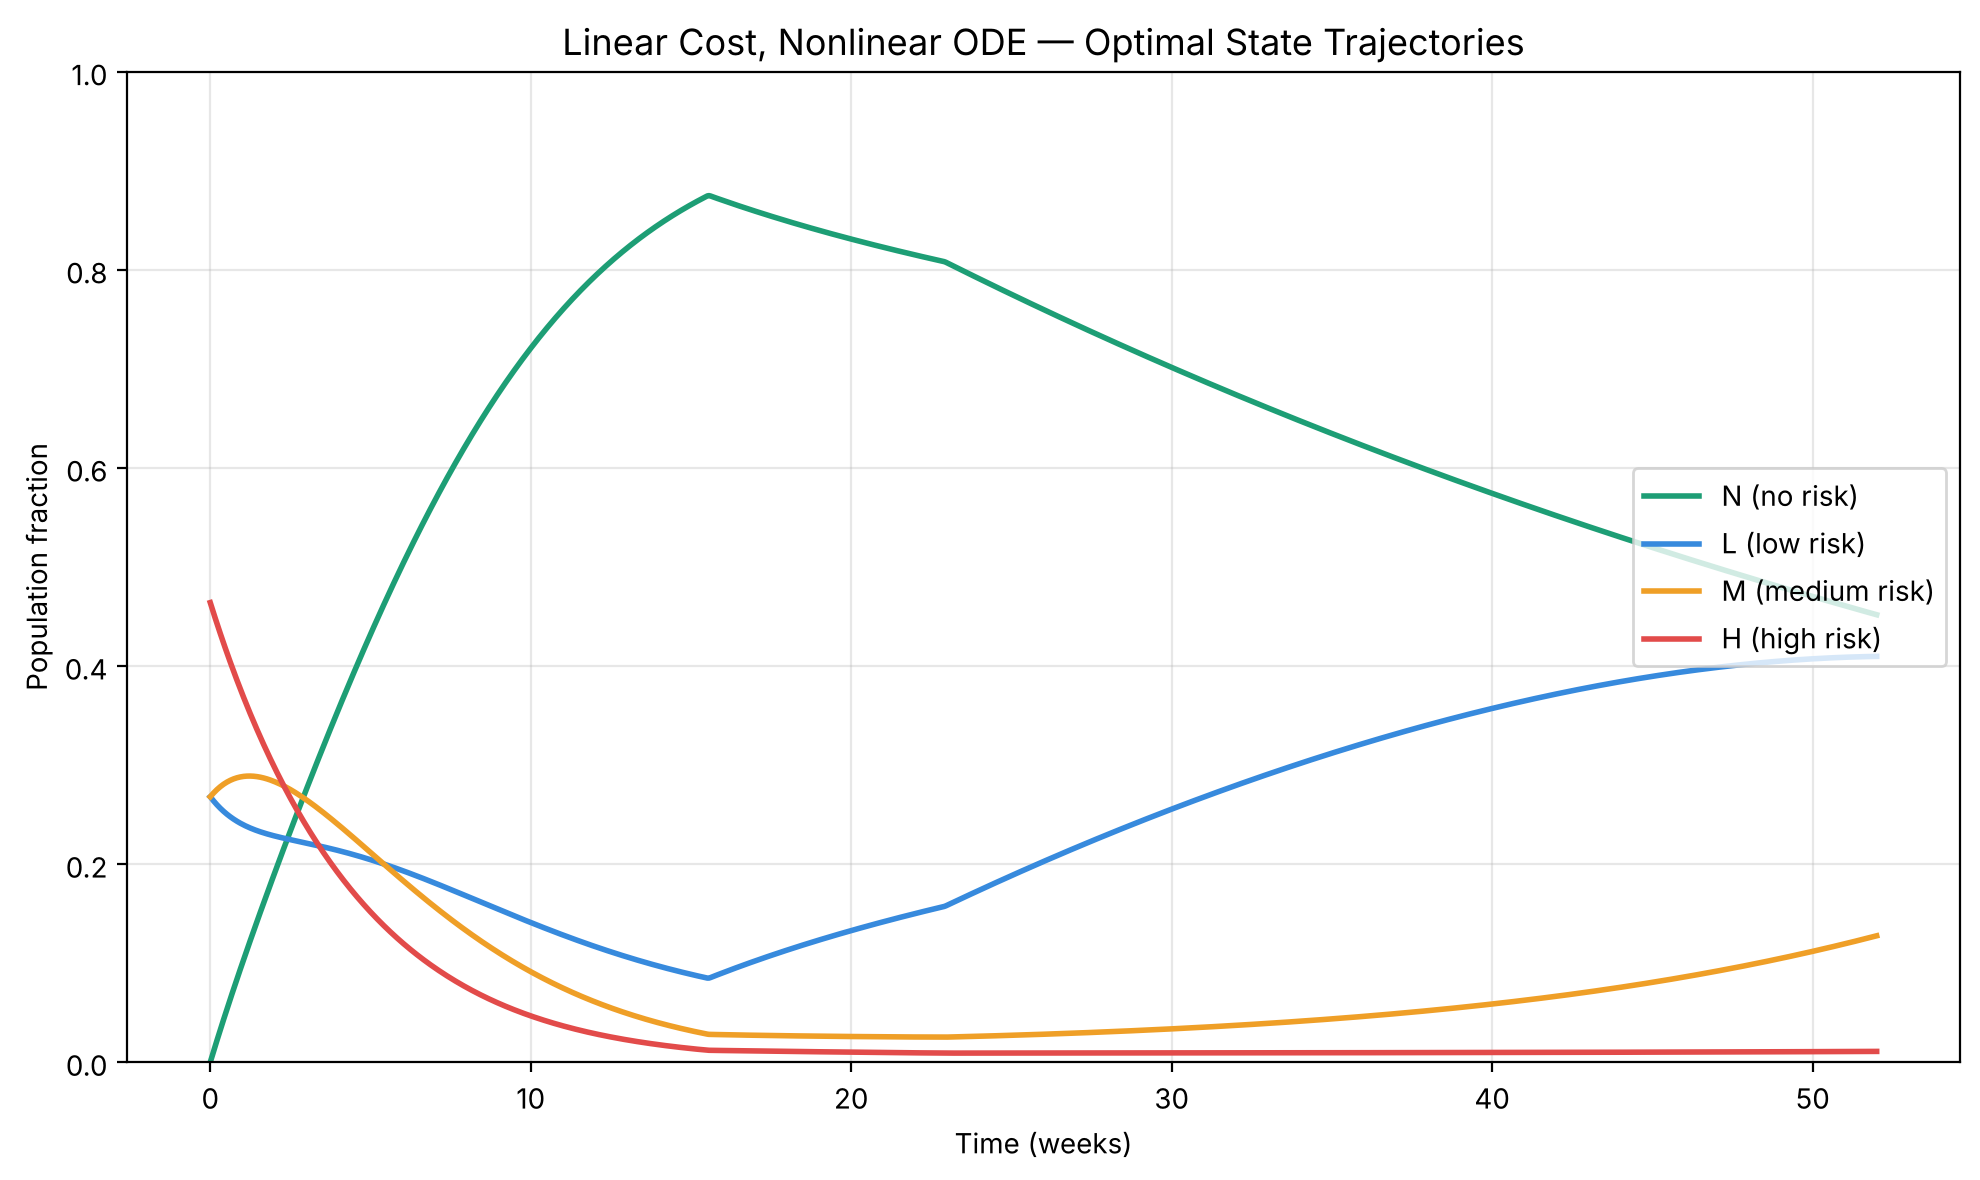

In [11]:
# --- Figure 1: State trajectories ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(t_grid, states['N'], color='#1D9E75', linewidth=2, label='N (no risk)')
ax.plot(t_grid, states['L'], color='#378ADD', linewidth=2, label='L (low risk)')
ax.plot(t_grid, states['M'], color='#EF9F27', linewidth=2, label='M (medium risk)')
ax.plot(t_grid, states['H'], color='#E24B4A', linewidth=2, label='H (high risk)')
ax.set_title("Linear Cost, Nonlinear ODE — Optimal State Trajectories", fontsize=13)
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Population fraction")
ax.legend(loc='right')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lin_cost_nonlin_ode_states.png", dpi=150)
plt.show()

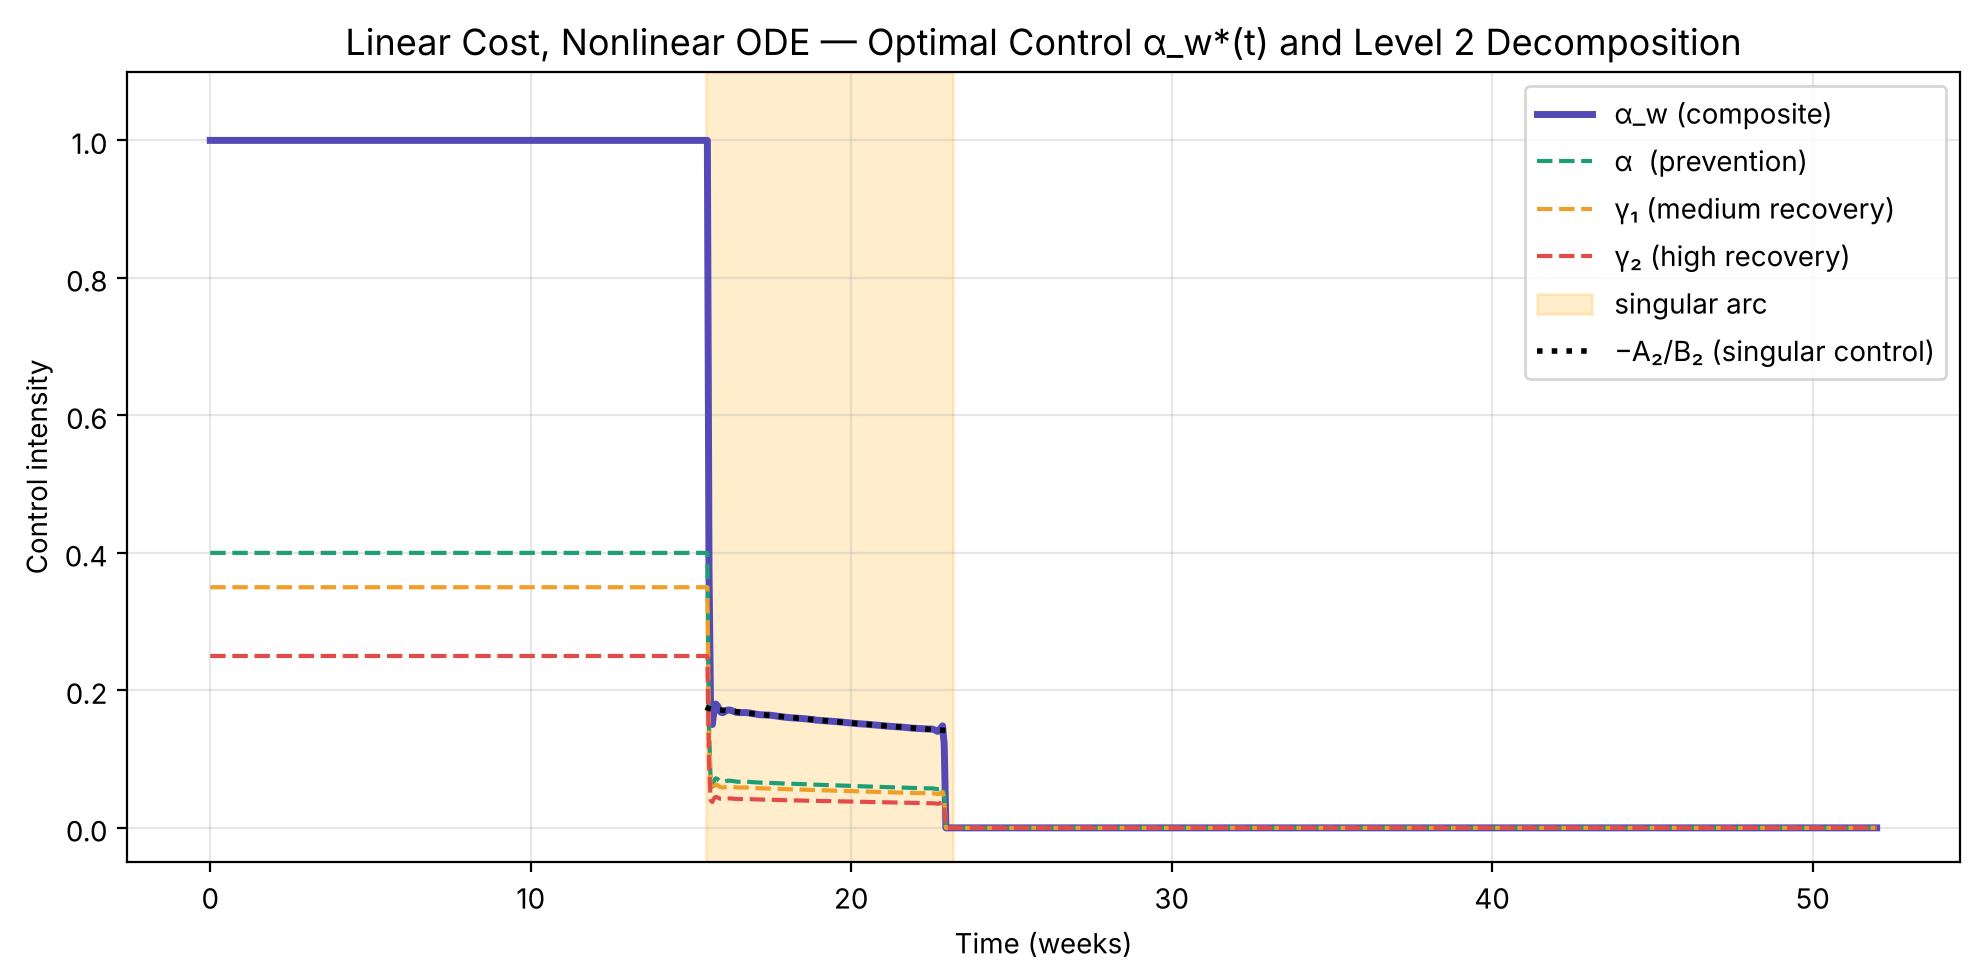

In [12]:
# --- Figure 2: Optimal control and its Level 2 decomposition ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t_grid, alpha_w_opt, label='α_w (composite)',      linewidth=2.5, color='#534AB7')
ax.plot(t_grid, alpha_opt,   label='α  (prevention)',      linewidth=1.5, linestyle='--', color='#1D9E75')
ax.plot(t_grid, gamma1_opt,  label='γ₁ (medium recovery)', linewidth=1.5, linestyle='--', color='#EF9F27')
ax.plot(t_grid, gamma2_opt,  label='γ₂ (high recovery)',   linewidth=1.5, linestyle='--', color='#E24B4A')
for k, (a, b) in enumerate(arcs):
    ax.axvspan(t_grid[a], t_grid[b], color='orange', alpha=0.2,
               label='singular arc' if k == 0 else None)
    ax.plot(t_grid[a:b+1], sing_traj[a:b+1], ':', color='k', linewidth=2,
            label='−A₂/B₂ (singular control)' if k == 0 else None)
ax.set_title("Linear Cost, Nonlinear ODE — Optimal Control α_w*(t) and Level 2 Decomposition", fontsize=13)
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Control intensity")
ax.set_ylim(-0.05, 1.1)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lin_cost_nonlin_ode_control.png", dpi=150)
plt.show()

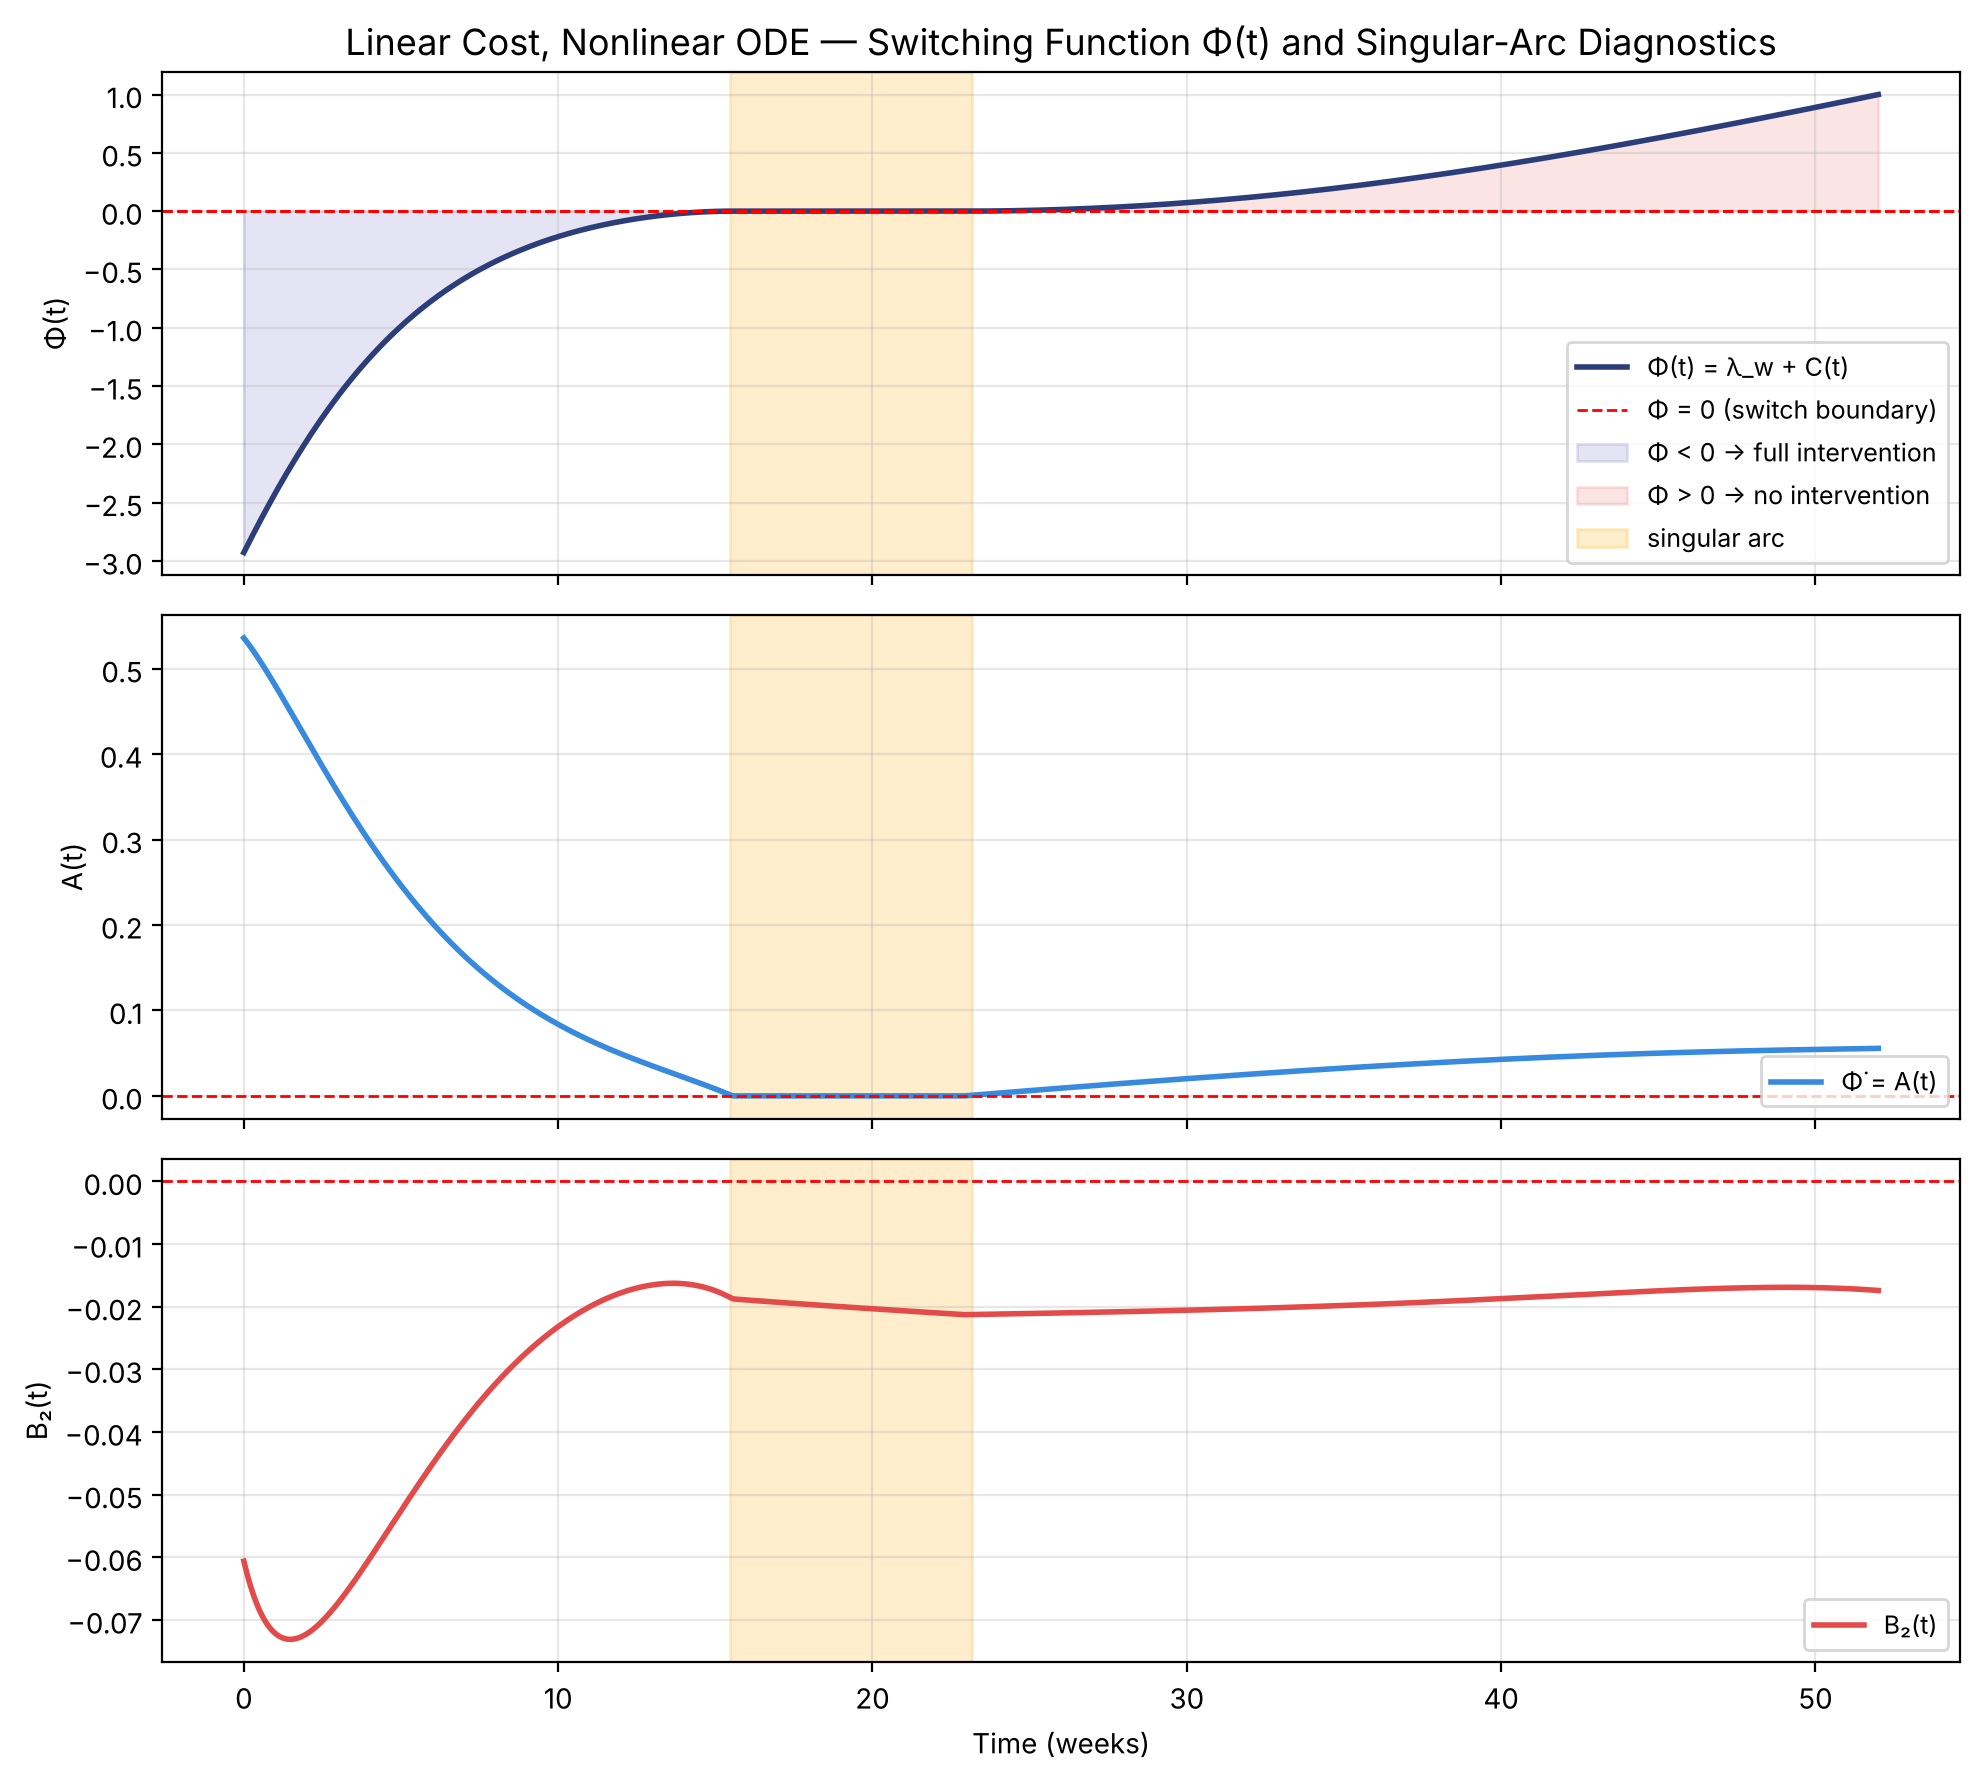

In [13]:
# --- Figure 3: Switching function and singular-arc diagnostics ---
fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax = axs[0]
ax.plot(t_grid, phi_traj, color='#2C3E7A', linewidth=2, label='Φ(t) = λ_w + C(t)')
ax.axhline(0, color='red', linestyle='--', linewidth=1, label='Φ = 0 (switch boundary)')
ax.fill_between(t_grid, phi_traj, 0, where=(phi_traj < -phi_tol), alpha=0.15,
                color='#534AB7', label='Φ < 0 → full intervention')
ax.fill_between(t_grid, phi_traj, 0, where=(phi_traj > phi_tol), alpha=0.15,
                color='#E24B4A', label='Φ > 0 → no intervention')
ax.set_ylabel("Φ(t)")
ax.set_title("Linear Cost, Nonlinear ODE — Switching Function Φ(t) and Singular-Arc Diagnostics", fontsize=13)
axs[1].plot(t_grid, A_traj, color='#378ADD', linewidth=2, label='Φ̇ = A(t)')
axs[1].set_ylabel("A(t)")
axs[2].plot(t_grid, B2_traj, color='#E24B4A', linewidth=2, label='B₂(t)')
axs[2].set_ylabel("B₂(t)")
axs[2].set_xlabel("Time (weeks)")
for k, a_ in enumerate(axs):
    a_.axhline(0, color='red', linestyle='--', linewidth=1)
    for j, (a, b) in enumerate(arcs):
        a_.axvspan(t_grid[a], t_grid[b], color='orange', alpha=0.2,
                   label='singular arc' if (k == 0 and j == 0) else None)
    a_.legend(fontsize=9, loc='lower right')
    a_.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lin_cost_nonlin_ode_switching.png", dpi=150)
plt.show()

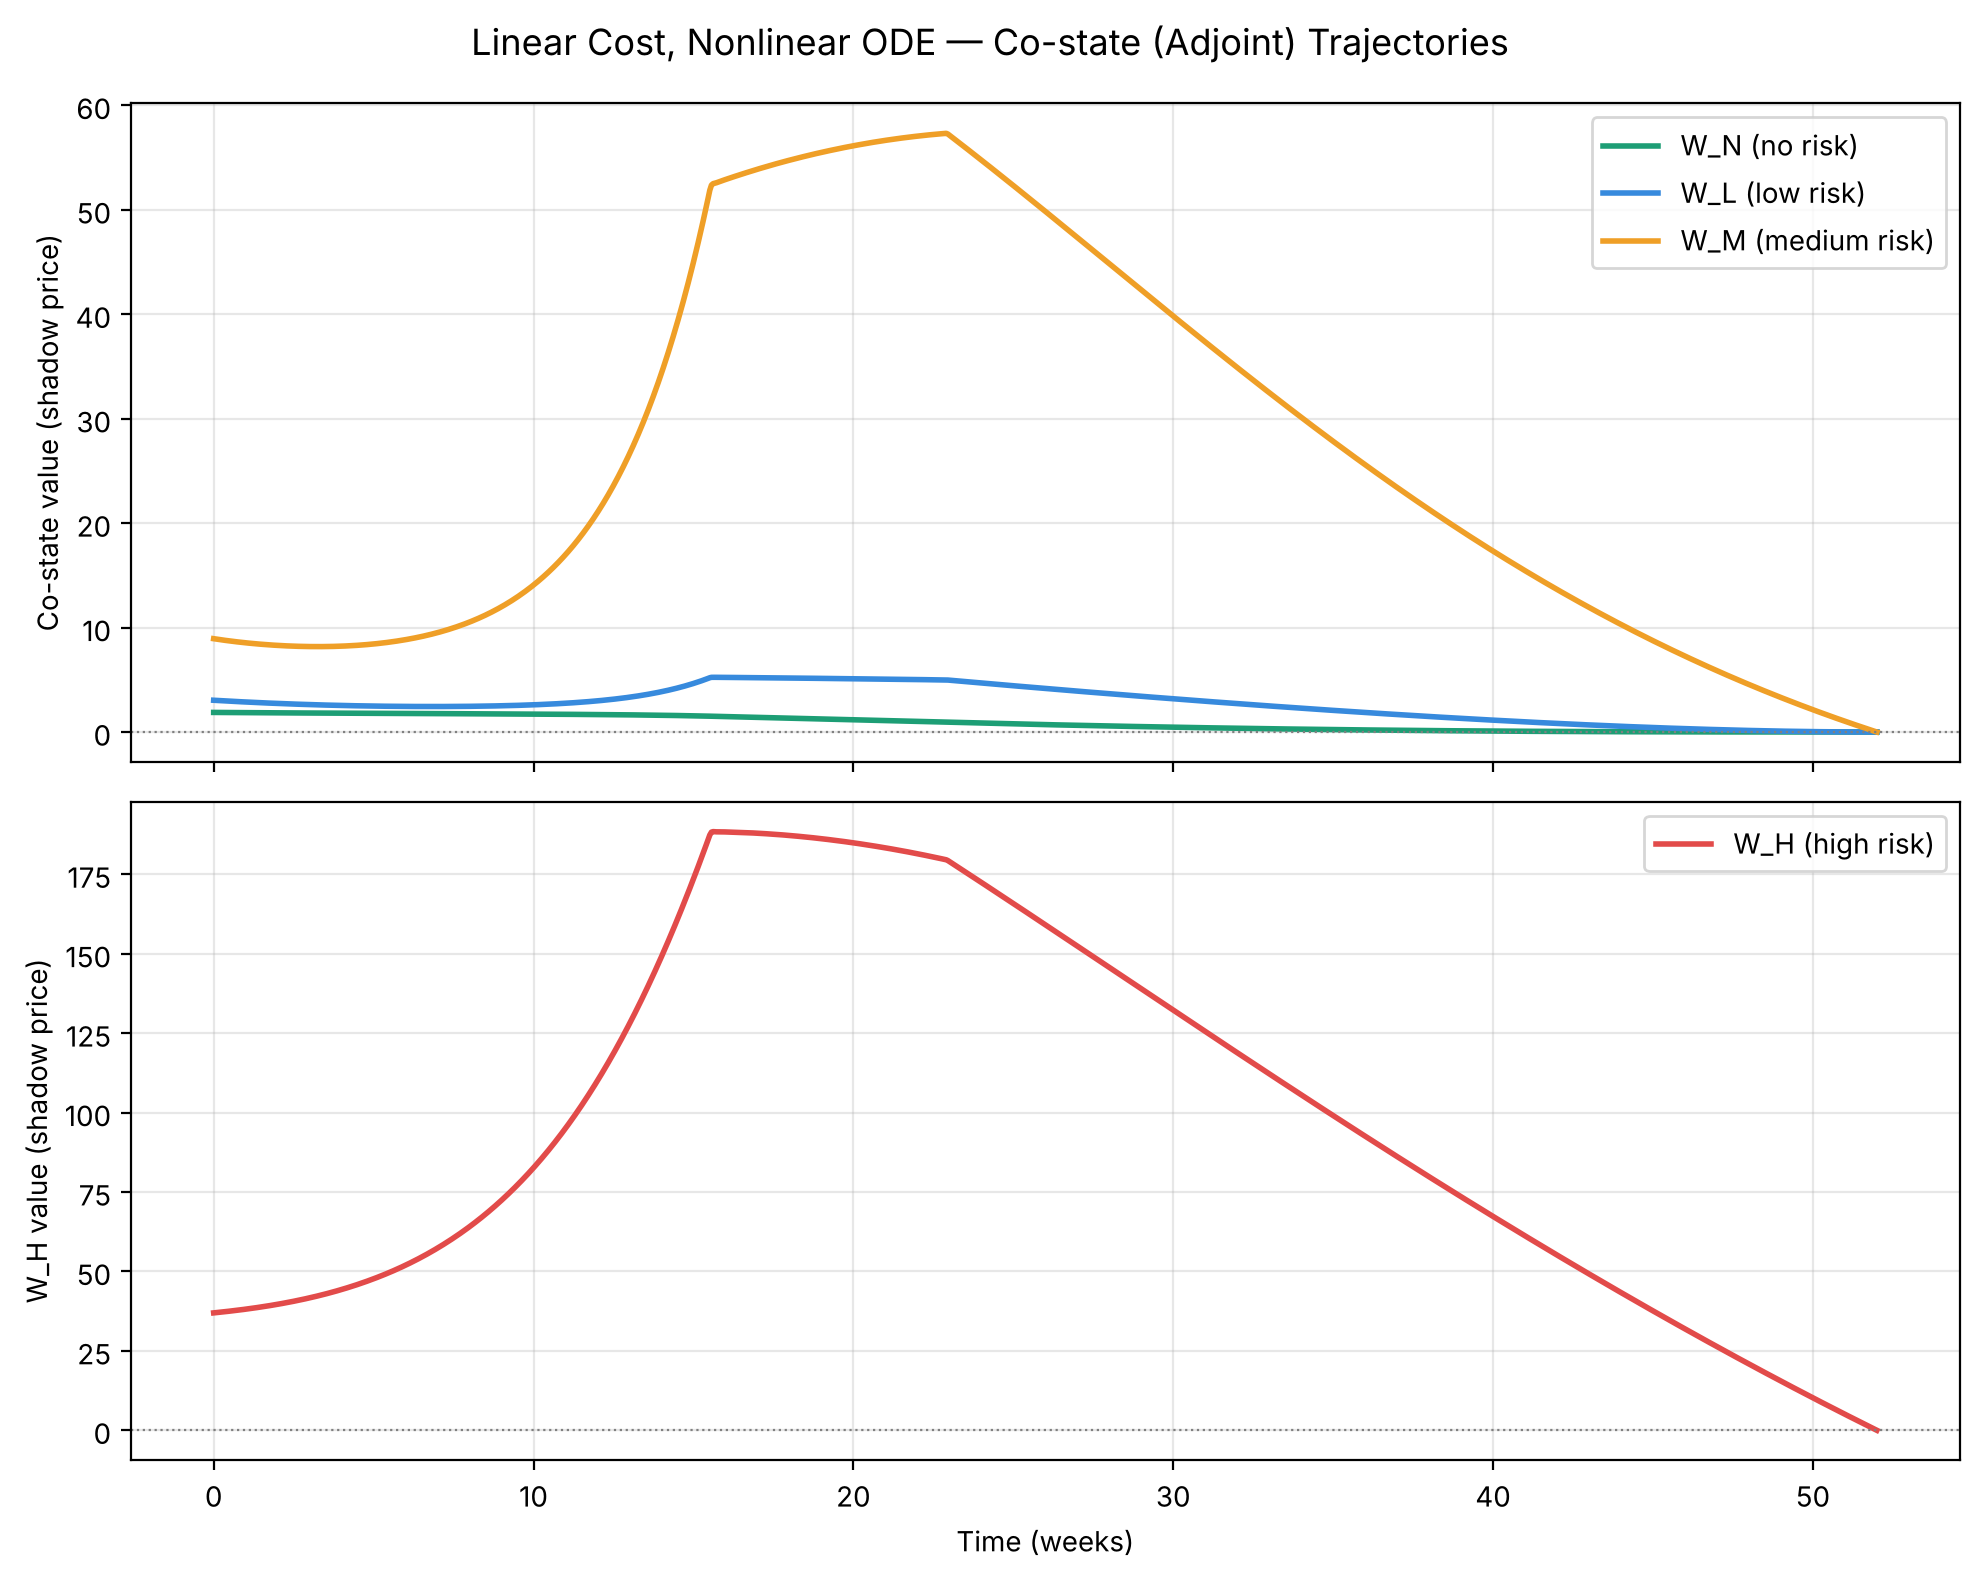

In [14]:
# --- Figure 4: Co-state trajectories ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle("Linear Cost, Nonlinear ODE — Co-state (Adjoint) Trajectories", fontsize=13)
ax1.plot(t_grid, costates['p_N'], color='#1D9E75', linewidth=2, label='W_N (no risk)')
ax1.plot(t_grid, costates['p_L'], color='#378ADD', linewidth=2, label='W_L (low risk)')
ax1.plot(t_grid, costates['p_M'], color='#EF9F27', linewidth=2, label='W_M (medium risk)')
ax1.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax1.set_ylabel("Co-state value (shadow price)")
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
ax2.plot(t_grid, costates['p_H'], color='#E24B4A', linewidth=2, label='W_H (high risk)')
ax2.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax2.set_xlabel("Time (weeks)")
ax2.set_ylabel("W_H value (shadow price)")
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lin_cost_nonlin_ode_costates.png", dpi=150)
plt.show()

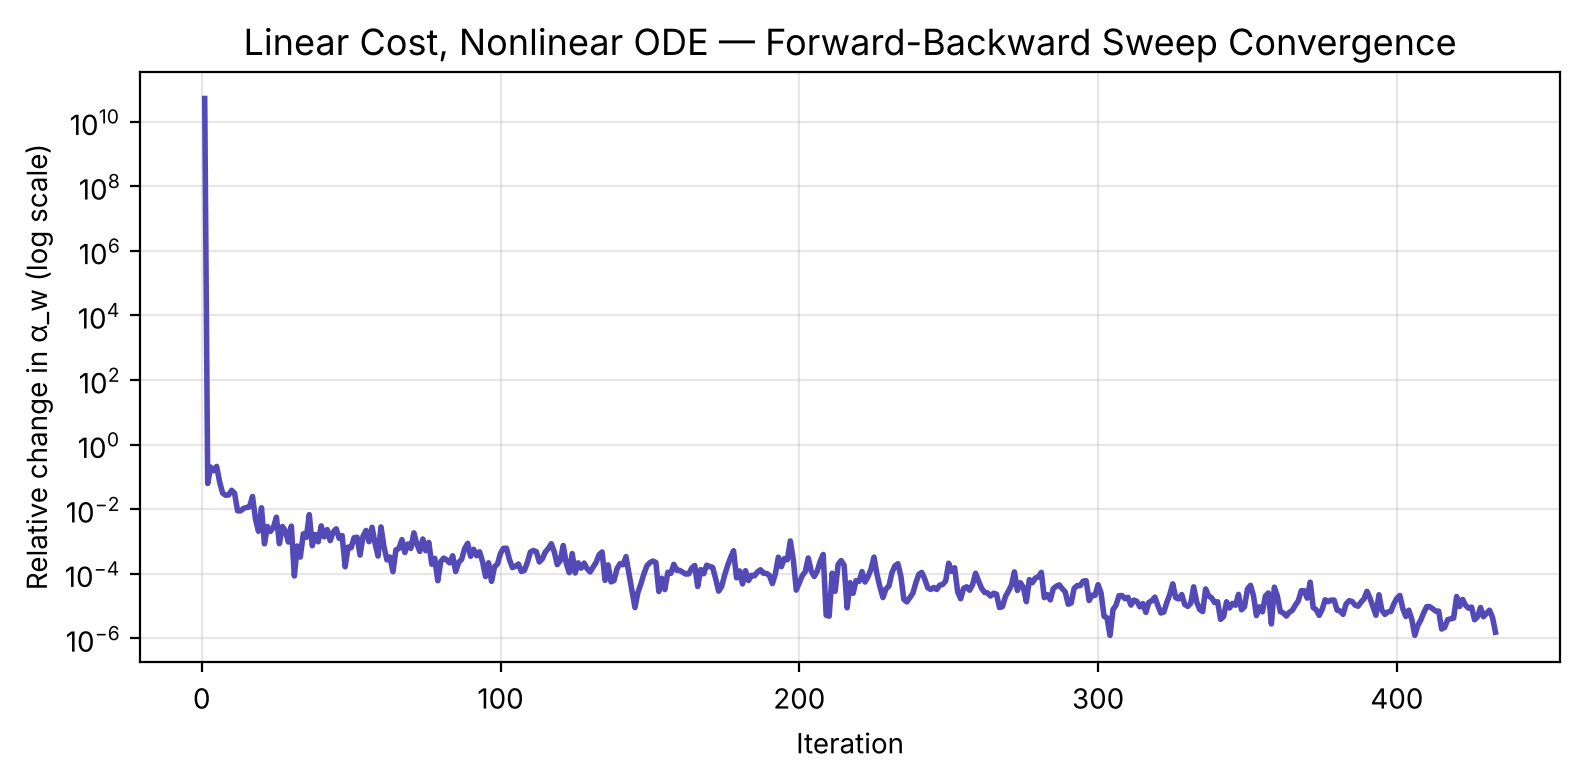

In [15]:
# --- Figure 5: Convergence ---
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(range(1, len(history) + 1), history, color='#534AB7', linewidth=2)
ax.set_title("Linear Cost, Nonlinear ODE — Forward-Backward Sweep Convergence", fontsize=13)
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative change in α_w (log scale)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("lin_cost_nonlin_ode_convergence.png", dpi=150)
plt.show()